In [41]:
from Model import Levels, Pick, UFloat
import numpy as np
import pandas as pd
from Model.utilities import n_, s_, mean
from tqdm.auto import tqdm
from PlotUtils.saveToCsv import saveToCsv, getNextFilename

from PlotUtils import errsPlot as plt, splt

splt.set_export_folder(".")

In [42]:
n_g = 2.687e25
T_g = 285

In [43]:
original_filename = '013'
# original_filename = '108'

data = pd.read_csv( f"Densities/{original_filename}.csv", index_col = False).to_dict('list')

data['density'] = [ UFloat.UFloat( n, s ) for n, s in zip( data['density_n'], data['density_s'] ) ]
data['label_idx'] = Levels.Levels().namesToIdxs( data['level'] )

In [44]:
f_es = np.logspace( -10, 0, 100 )
T_es = np.logspace( np.log10( 0.11), np.log10( 19.8 ), 100 )

In [45]:
chisquared = np.zeros( ( len( f_es ), len( T_es ) ) )
reps = 100

for k in tqdm( range( reps ), total = reps ):
    pas = Pick.Pick()
    for i, f_e in enumerate( f_es ):
        for j, T_e in enumerate( T_es ):
            chisquared[ i, j ] += pas.chiSquared_frompars( data['density'], data['label_idx'], n_g, f_e, T_e, T_g )


for i, f_e in enumerate( f_es ):
    for j, T_e in enumerate( T_es ):
        chisquared[ i, j ] = chisquared[ i, j ] / reps

  0%|          | 0/100 [00:01<?, ?it/s]

In [46]:
f_esm, T_esm = np.meshgrid( f_es, T_es )
filename = saveToCsv( { 'f_es': f_esm.flatten(), 'T_es': T_esm.flatten(), 'chisquared': chisquared.flatten() }, basename = f"Densities_chi2/{original_filename}_chi" )

Saved as Densities_chi2/013_chi001


./Densities_chi2/013_chi001_chisquared_countourf.pdf


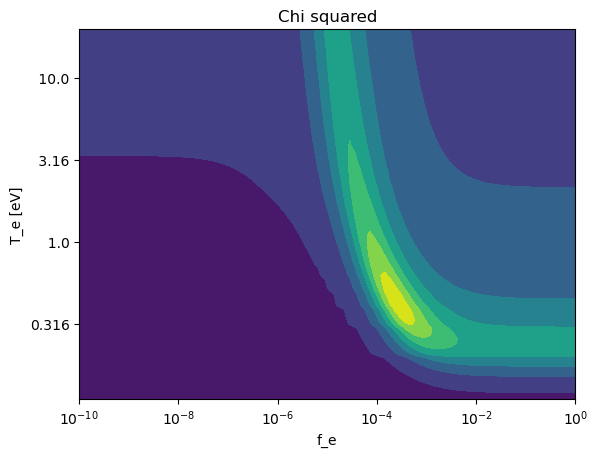

In [47]:
plt.contourf( np.log10( f_es ), np.log10( T_es ), 1 / chisquared.T )

xticks = plt.xticks( )
plt.xticks( xticks[0], [ f"$10^{{{x.get_text()}}}$" for x in xticks[1] ] )
yticks = plt.yticks( )[0][1:-1]
plt.yticks( yticks, [ f"{x:5.3}" for x in 10**yticks ] )

plt.xlabel("f_e")
plt.ylabel("T_e [eV]")

plt.title("Chi squared")

splt.export( filename + "_chisquared_countourf" )

In [48]:
chisquared_f_e = np.min( chisquared, axis = 1 )
chisquared_T_e = np.min( chisquared, axis = 0 )

chisquared_f_e_idx = np.where( 1 / chisquared_f_e > 1 / np.min( chisquared_f_e ) * 0.75 )
chisquared_T_e_idx = np.where( 1 / chisquared_T_e > 1 / np.min( chisquared_T_e ) * 0.75 )

./Densities_chi2/013_chi001_1OverChisquared_3d.pdf


Text(0, 0.5, 'Maximum of chisquared varying f_e')

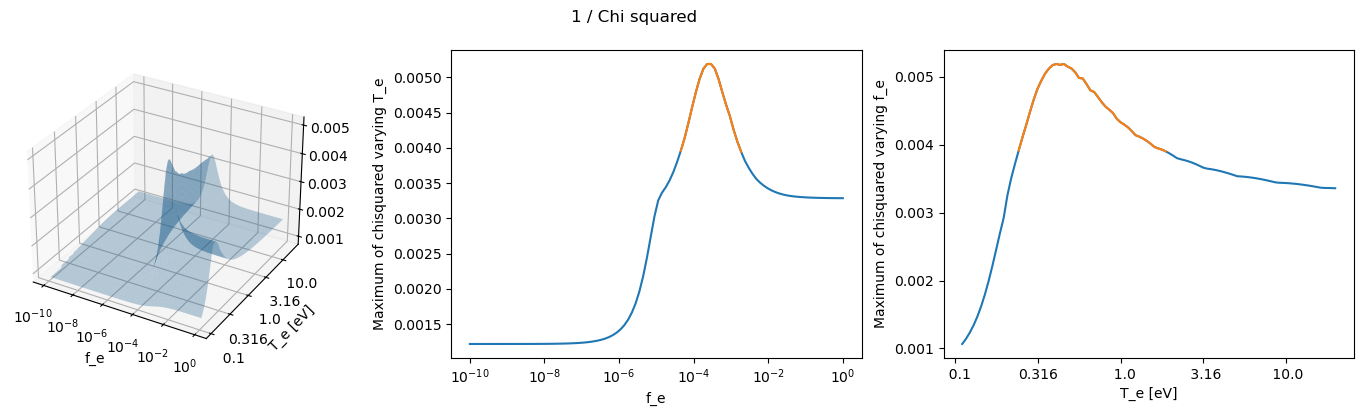

In [49]:
ax = plt.figure( figsize = ( 18, 4 ) ).add_subplot(1, 3, 1, projection='3d')
ax.plot_surface( *np.meshgrid(np.log10( f_es), np.log10( T_es)), 1 / chisquared.T, alpha=0.3 )


xticks = plt.xticks( )
plt.xticks( xticks[0][1:-1], [ f"$10^{{{x.get_text()}}}$" for x in xticks[1][1:-1] ] )
yticks = plt.yticks( )[0][1:-1]
plt.yticks( yticks, [ f"{x:5.3}" for x in 10**yticks ] )


plt.xlabel("f_e")
plt.ylabel("T_e [eV]")

plt.suptitle("1 / Chi squared")

splt.export( filename + "_1OverChisquared_3d" )

ax = plt.gcf().add_subplot( 1, 3, 2 )
plt.plot( np.log10( f_es ), 1 / chisquared_f_e )
plt.plot( np.log10( f_es )[chisquared_f_e_idx], 1 / chisquared_f_e[chisquared_f_e_idx] )

xticks = plt.xticks( )
plt.xticks( xticks[0][1:-1], [ f"$10^{{{x.get_text()}}}$" for x in xticks[1][1:-1] ] )
plt.xlabel("f_e")
plt.ylabel("Maximum of chisquared varying T_e")

ax = plt.gcf().add_subplot( 1, 3, 3 )
plt.plot( np.log10( T_es ), 1 / chisquared_T_e )
plt.plot( np.log10( T_es )[chisquared_T_e_idx], 1 / chisquared_T_e[chisquared_T_e_idx] )

xticks = plt.xticks( )[0][1:-1]
plt.xticks( xticks, [ f"{x:5.3}" for x in 10**xticks ] )
plt.xlabel("T_e [eV]")
plt.ylabel("Maximum of chisquared varying f_e")


In [50]:
n_atmax_all = np.array([ Pick.Pick().getEquilibrium( n_g, f_es[ np.argmax( np.max( 1 / chisquared, axis = 1 ) )], T_es[ np.argmax( np.max( 1 / chisquared, axis = 0 ) )], T_g )[ data['label_idx'] ] for i in range(100) ])
n_atmax = [ mean( n_atmax_all[:,i] ) for i in range( np.shape( n_atmax_all )[1] ) ]

In [51]:
print( n_g, f_es[ np.argmax( np.max( 1 / chisquared, axis = 1 ) )], T_es[ np.argmax( np.max( 1 / chisquared, axis = 0 ) )], T_g )

2.687e+25 0.0002310129700083158 0.4533848508227764 285


In [52]:
def scalefact( measured_levels, simulated_levels ):
    normfact = s_( measured_levels )
    simulated_levels = n_( simulated_levels )
    return np.sum( n_( measured_levels ) * simulated_levels / normfact / normfact ) / np.sum( simulated_levels * simulated_levels / normfact / normfact )


<ErrorbarContainer object of 3 artists>

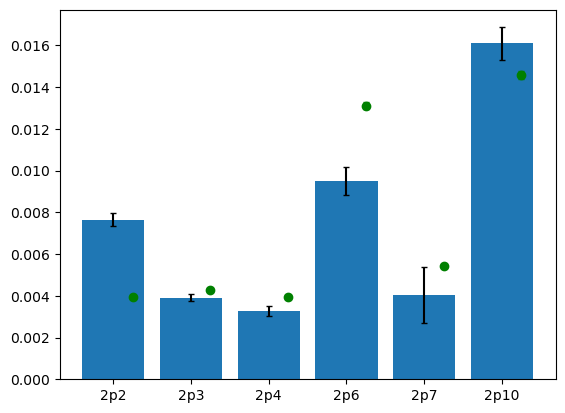

In [53]:
plt.bar( data['level'], data['density'] )
plt.plot( np.arange( len( data['level'] ) ) + 0.25, [ k * scalefact( data['density'], n_atmax ) for k in n_atmax ], fmt = 'go' )